# 04c - Classificação: risco de *default* na concessão

Prever, no momento da concessão (T4), se um empréstimo de 36 meses acaba em **Default** ou em **Good standing**. Nesse momento já se conhecem a taxa de juro, o grau e a prestação, por isso entram como inputs (ao contrário da regressão).

Todos os modelos passam pelo mesmo `CrossValidationRunner` (`src/lending/experiment.py`), com os mesmos 3 folds anuais e o mesmo pré-processamento. Os modelos e as grelhas estão em `src/lending/model_catalog.py`.

| Requisito do enunciado | Onde |
|---|---|
| *"Use the same eligible evaluation cohort and split definitions for all models within a task"* | Secção 1: a coorte e os folds são os mesmos para todos os modelos |
| *"Prepare one comparison table for each task, including baselines"* | Secção 2: as baselines são as primeiras linhas da tabela |
| *"Classification: confusion matrix, precision, recall, F1 (macro and micro averages), AUC, and accuracy"* | Métricas calculadas pelo runner (`src/lending/evaluation.py`) |
| *"Present the mean and the variation of the metric in the cross-validation procedures"* | `comparison_table()`: média ± desvio-padrão nos 3 folds |
| *"Report training sample sizes, tuning procedures, and any computational limitations"* | Colunas `n_train` e `fit_seconds`; a grelha de cada modelo |

**Antes de correr:** `01_preprocessamento.ipynb` (gera `classificacao_treino.pkl`).

**Ficheiros:** os resultados vão para `reports/results/classification_cv.csv` (entra no Git) e as previsões fora do fold para `data/processed/oof/classification/` (fora do Git). O runner retoma onde parou: as combinações (modelo, configuração, fold) que já estão no CSV não voltam a correr.

In [1]:
# Setup: imports e caminhos do projeto
import json
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import pandas as pd

from lending import config
from lending.baselines import GradeRateBaseline
from lending.evaluation import classification_metrics
from lending.experiment import CrossValidationRunner
from lending.model_catalog import classification_specs
from lending.plot_style import apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

## 1. Coorte e folds

**Coorte.** São os 31 522 empréstimos de 36 meses concedidos entre 2007-06 e 2011-12. Todos acabaram o prazo antes do corte de observação (31/12/2018), por isso o desfecho de cada um já é conhecido. Os empréstimos de 2012 a 2014 ficam de fora (embargo): na data de treino simulada (01/01/2015) ainda não tinham terminado.

**Alvo binário.** A classe *At risk* tem 0 casos no treino (só aparece em empréstimos ainda ativos), por isso a classificação é *Good standing* contra *Default*. No teste de 2015, os *At risk* contam como *Default*.

**Folds: janela expansível anual.** Cada fold treina com todos os anos anteriores e valida no ano seguinte. Nunca se treina com empréstimos posteriores aos da validação, ao contrário do que aconteceria numa validação cruzada com folds aleatórios, que deixaria o modelo aprender com o futuro.

O runner ordena sempre as linhas por `issue_d` antes de criar os folds. É disso que depende a paragem antecipada da MLP e do LightGBM, que usa os 15% mais recentes do treino de cada fold.

In [2]:
data = PickleStore.load(config.CLS_TRAIN_PKL, expected_type=pd.DataFrame)
print(f"{len(data):,} empréstimos, {data.shape[1]} colunas")

counts = data[config.CLASS_COL].value_counts().reindex(config.CLASS_ORDER)
pd.DataFrame({"empréstimos": counts, "%": (100 * counts / counts.sum()).round(1)})

31,522 empréstimos, 152 colunas


,empréstimos,%
target,,
Good standing,27646,87.7
Default,3876,12.3


Tabela dos folds, com a taxa de *default* de cada lado e o peso que os modelos dão a um *Default* quando usam `class_weight="balanced"`.

O peso "balanced" de uma classe é $w_c = \dfrac{n}{2\, n_c}$ ($n$ linhas de treino, $n_c$ da classe $c$). Com 12% de *Default*, cada *Default* pesa cerca de 4 e cada *Good standing* cerca de 0,6. Assim, as duas classes contam o mesmo na função de perda, sem duplicar nem apagar linhas (não há reamostragem).

In [3]:
runner = CrossValidationRunner("classification")
folds = runner.folds(data)

# Taxa de default e peso "balanced" de cada fold (os folds usam os dados ordenados por issue_d)
ordered = runner.prepare(data)
is_default = ordered[config.CLASS_COL].eq("Default")
extra = []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    rate = is_default.iloc[tr].mean()
    extra.append({"fold": fold,
                  "default no treino (%)": round(100 * rate, 1),
                  "default na validação (%)": round(100 * is_default.iloc[va].mean(), 1),
                  "peso de Default": round(1 / (2 * rate), 2),
                  "peso de Good standing": round(1 / (2 * (1 - rate)), 2)})
folds.join(pd.DataFrame(extra).set_index("fold"))

,treino,validação,linhas treino,linhas validação,default no treino (%),default na validação (%),peso de Default,peso de Good standing
fold,,,,,,,,
1,2007 a 2008,2009,2991,5280,21.9,13.7,2.29,0.64
2,2007 a 2009,2010,8271,9153,16.6,10.9,3.00,0.60
3,2007 a 2010,2011,17424,14098,13.6,10.6,3.67,0.58


**Leitura.**

- **Desequilíbrio:** 12,3% de *Default*, cerca de 1 para 7. Um modelo que nunca prevê *Default* acerta em 88% dos casos, por isso a *accuracy* sozinha não serve para escolher modelos.
- **Mudança temporal:** a taxa de *default* desce de 21,9% no treino do fold 1 (2007–2008, os anos da crise financeira) para 13,6% no do fold 3. As validações ficam entre 10,6% e 13,7%. O treino de cada fold tem sempre mais *default* do que o ano que se segue, por isso um modelo treinado nos anos maus tende a sobrestimar o risco do ano seguinte.
- **Fold 1 pequeno:** treina com 2 991 empréstimos, menos de um quinto do fold 3. É de esperar mais variação entre folds nos modelos mais flexíveis (MLP, LightGBM), e isso deve ser reportado.
- **Pesos:** o peso de *Default* sobe de 2,3 para 3,7 porque a proporção de *Default* no treino desce.

## 2. Baselines

As baselines são a linha de referência da tabela de comparação (critérios de sucesso em `docs/01_formulacao_problema/definicao_tarefas.md`):

- **Classe maioritária** (`DummyClassifier(strategy="most_frequent")`): prevê sempre *Good standing*. A probabilidade de *Default* é 0 para todos, por isso a AUC é 0,5. Mostra porque é que a *accuracy* engana com classes desequilibradas: acerta em cerca de 88% dos casos sem identificar um único *Default*.
- **Taxa do grau** (`GradeRateBaseline`): a probabilidade de *Default* é a taxa de *default* do grau (A a G) no treino do fold. Representa a avaliação de risco da própria LendingClub. Um modelo só acrescenta valor se fizer melhor do que o grau.

As duas leem colunas originais (`grade`), por isso não passam pelo pré-processamento (`preprocess=False`).

**Limiar.** No CSV, as métricas que dependem do limiar usam 0,5. Na tabela de comparação, o runner escolhe para cada configuração o limiar (de 0,05 a 0,95) que maximiza o F1 macro nas previsões fora do fold dos 3 folds juntos, e recalcula as métricas de cada fold com esse limiar. A AUC não depende do limiar.

In [4]:
specs = {spec.name: spec for spec in classification_specs()}
BASELINES = ["Classe maioritária", "Taxa do grau"]
runner.run(data, [specs[name] for name in BASELINES]);

In [5]:
# Taxa de default de cada grau no treino do último fold (2007-2010): é o que a baseline prevê
tr, va = list(runner.splitter.split(ordered["issue_d"]))[-1]
grade_model = GradeRateBaseline().fit(ordered.iloc[tr][runner.columns], ordered[config.CLASS_COL].iloc[tr])
grades = ordered.iloc[tr]["grade"].value_counts().sort_index()
pd.DataFrame({"empréstimos": grades, "default (%)": (100 * grade_model.rates_).round(1)})

,empréstimos,default (%)
A,4166,5.2
B,4940,11.4
C,4136,15.5
D,2586,20.2
E,1027,23.3
F,359,32.9
G,210,35.7


In [6]:
# Resultados por fold, com o limiar de 0,5 (uma linha do CSV por modelo e fold)
cols = ["model", "fold", "valid_period", "n_train", "n_valid", "f1_macro", "f1_micro",
        "accuracy", "recall_default", "auc"]
runner.results().query("model in @BASELINES")[cols].round(3)

,model,fold,valid_period,n_train,n_valid,f1_macro,f1_micro,accuracy,recall_default,auc
0,Classe maioritária,1,2009,2991,5280,0.463,0.863,0.863,0.0,0.500
1,Taxa do grau,1,2009,2991,5280,0.463,0.863,0.863,0.0,0.616
2,Classe maioritária,2,2010,8271,9153,0.471,0.891,0.891,0.0,0.500
3,Taxa do grau,2,2010,8271,9153,0.471,0.891,0.891,0.0,0.654
4,Classe maioritária,3,2011,17424,14098,0.472,0.894,0.894,0.0,0.500
5,Taxa do grau,3,2011,17424,14098,0.472,0.894,0.894,0.0,0.622


In [7]:
# Tabela de comparação: média ± desvio-padrão nos 3 folds, com o limiar escolhido
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


In [8]:
def per_fold(model, cid=None):
    """
    Métricas de cada fold com o limiar escolhido na validação cruzada (o mesmo nos 3 folds)

    Lê as previsões fora do fold guardadas pelo runner; não treina nada.

    Parameters:
        model (str): Nome do modelo no catálogo
        cid (str | None): Configuração; por omissão, a melhor do modelo (F1 macro médio)
    """
    if cid is None:
        cid = runner.best().set_index("model").loc[model, "config_id"]
    threshold = runner.threshold(model, cid)
    rows = []
    for fold, part in runner.oof(model, cid).groupby("fold"):
        metrics = classification_metrics(part["y_true"], part["p_default"], threshold)
        rows.append({"fold": fold, "limiar": threshold,
                     "previstos Default (%)": round(100 * (part["p_default"] >= threshold).mean(), 1),
                     **{m: round(metrics[m], 3) for m in ["f1_macro", "accuracy", "recall_default", "auc"]}})
    return pd.DataFrame(rows).set_index("fold")


# Taxa do grau, fold a fold, com o limiar escolhido
per_fold("Taxa do grau")

,limiar,previstos Default (%),f1_macro,accuracy,recall_default,auc
fold,,,,,,
1,0.21,49.9,0.471,0.541,0.645,0.616
2,0.21,18.7,0.559,0.778,0.338,0.654
3,0.21,2.4,0.508,0.880,0.049,0.622


**Leitura.**

- **Classe maioritária:** *accuracy* de 0,88, mas recall de *Default* 0 e F1 macro 0,47. É a armadilha das classes desequilibradas: a *accuracy* é alta e o modelo não serve para nada.
- **O grau ordena bem o risco:** a taxa de *default* sobe sempre de A (5,2%) para G (35,7%). Daí a AUC de 0,63 ± 0,02 da baseline.
- **Com o limiar de 0,5, a taxa do grau é igual à classe maioritária:** nenhum grau chega a 50% de *default*, por isso prevê sempre *Good standing*. As métricas que dependem do limiar ficam iguais às da classe maioritária e só a AUC as distingue. É por isso que o limiar se escolhe e não se fixa em 0,5.
- **Com o limiar escolhido (0,21):** o F1 macro sobe para 0,51 ± 0,05, mas o recall de *Default* varia muito, 0,34 ± 0,30. A tabela por fold mostra porquê:
    - no fold 1, o treino é de 2007–2008 e as taxas de cada grau são altas (C já tem 21,7%). Os graus C a G passam o limiar e metade dos empréstimos de 2009 são marcados como *Default*;
    - no fold 3, as taxas já desceram (C tem 15,5%) e só F e G passam o limiar: 2,4% dos empréstimos são marcados.
- **Conclusão para o resto do bloco:** a ordenação do risco (AUC) é estável de ano para ano (0,62 a 0,65), mas o nível das probabilidades muda com o tempo. Um limiar fixo dá decisões muito diferentes de um ano para o outro, e isso vai pesar no teste de 2015. Por isso, a AUC é a medida mais estável e o F1 macro tem de ser lido com o desvio-padrão ao lado.
- **A fasquia:** para acrescentar alguma coisa à avaliação da própria LendingClub, um modelo tem de passar a AUC de 0,63 e o F1 macro de 0,51 da taxa do grau.
- Em classificação binária, o F1, a precisão e o recall *micro* são iguais à *accuracy* (cada erro é ao mesmo tempo um falso positivo de uma classe e um falso negativo da outra). Não é um erro de cálculo.
- O limiar é escolhido nas mesmas previsões fora do fold em que se mede o F1, por isso o F1 da validação cruzada fica ligeiramente otimista. O limiar nunca é mudado com o teste.

## 3. Modelos do scikit-learn que não são ensembles

O enunciado pede pelo menos dois modelos supervisionados do scikit-learn que não sejam ensembles. Na classificação são a regressão logística e a árvore de decisão. Os dois passam pelo pré-processamento da Parte 1 (imputação, *clipping*, padronização e *one-hot*), ajustado só no treino de cada fold.

**Regressão logística com penalização L2.** Modela o *log-odds* do *Default* como uma soma ponderada das features:

$$\log \frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_m x_m, \qquad p = \frac{1}{1 + e^{-(\beta_0 + \beta \cdot x)}}$$

- Os coeficientes minimizam a *log-loss* mais uma penalização $\tfrac{1}{2}\lVert\beta\rVert^2$. O `C` é o inverso da força da penalização: com `C` pequeno, os coeficientes são puxados para 0 (modelo mais simples); com `C` grande, quase não há penalização. A grelha tem `C` de $10^{-3}$ a $10^{2}$.
- A penalização L2 estabiliza os coeficientes quando há colunas correlacionadas (FICO *low*/*high*, as colunas do *one-hot*). Como o pipeline padroniza as colunas, a penalização trata todas por igual.
- Sai o `dti_with_loan`, que é exatamente `dti + installment_to_income`. Com uma combinação linear exata, há infinitos conjuntos de coeficientes que dão as mesmas previsões, e os *odds ratios* dessas colunas deixariam de ter leitura.
- `class_weight="balanced"`: a perda de cada *Default* conta cerca de 4 vezes. O modelo passa a comportar-se como se as duas classes tivessem a mesma frequência, por isso as probabilidades deixam de estimar a probabilidade real de *Default* e ficam deslocadas para cima. A AUC (ordenação) quase não muda, mas o limiar tem de ser escolhido.

**Árvore de decisão.** Divide os dados, passo a passo, com perguntas do tipo "feature ≤ valor". Em cada nó escolhe a pergunta que mais reduz a impureza de Gini. Cada folha dá a proporção (ponderada) de *Default* dos empréstimos de treino que lá caem.

- Sem limites, a árvore cresce até decorar o treino (sobreajustamento). A grelha controla isso com `max_depth` {4, 6, 8, 12}, o número máximo de perguntas seguidas, e `min_samples_leaf` {50, 200}, o mínimo de empréstimos por folha.
- Não precisa de padronização nem de relações lineares e capta interações (ex.: FICO baixo e taxa alta ao mesmo tempo). Por isso mantém o `dti_with_loan`.
- As probabilidades só têm tantos valores diferentes quantas as folhas, o que limita a ordenação fina (AUC).

In [9]:
LINEAR_TREE = ["Regressão logística", "Árvore"]
runner.run(data, [specs[name] for name in LINEAR_TREE]);

In [10]:
def grid_table(model):
    """ Uma linha por configuração da grelha: parâmetros, limiar escolhido e média/desvio nos 3 folds. """
    summary = runner.summary().query("model == @model")
    params = pd.DataFrame(list(summary["params"].map(json.loads)), index=summary.index)
    cols = ["threshold", "f1_macro_mean", "f1_macro_std", "auc_mean", "auc_std",
            "recall_default_mean", "fit_seconds"]
    return (pd.concat([params, summary[cols]], axis=1)
            .sort_values(list(params.columns)).round(3).reset_index(drop=True))


grid_table("Regressão logística")

,C,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,0.001,0.54,0.567,0.006,0.664,0.026,0.270,0.059
1,0.010,0.53,0.569,0.007,0.671,0.023,0.322,0.080
2,0.100,0.56,0.570,0.010,0.669,0.021,0.259,0.110
3,1.000,0.54,0.569,0.007,0.664,0.021,0.284,0.152
4,10.000,0.54,0.569,0.006,0.661,0.021,0.269,0.169
5,100.000,0.54,0.569,0.006,0.661,0.021,0.271,0.204


In [11]:
grid_table("Árvore")

,max_depth,min_samples_leaf,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,4,50,0.52,0.538,0.013,0.625,0.018,0.194,0.105
1,4,200,0.52,0.529,0.016,0.623,0.020,0.236,0.100
2,6,50,0.62,0.541,0.011,0.613,0.007,0.187,0.121
3,6,200,0.58,0.529,0.016,0.624,0.013,0.200,0.115
4,8,50,0.66,0.540,0.007,0.603,0.011,0.176,0.156
5,8,200,0.58,0.541,0.023,0.623,0.014,0.288,0.130
6,12,50,0.68,0.535,0.004,0.589,0.010,0.186,0.164
7,12,200,0.58,0.541,0.023,0.623,0.012,0.284,0.147


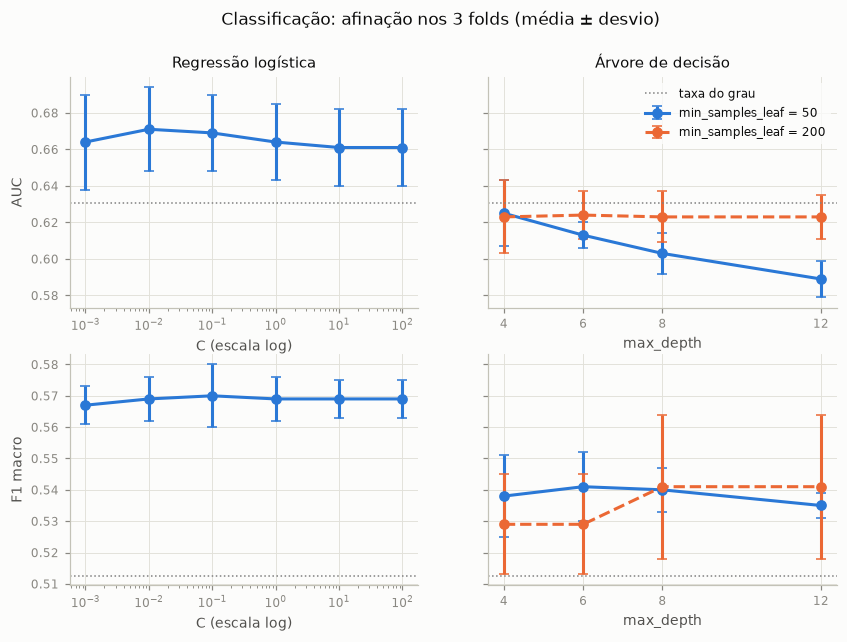

In [12]:
# Afinação: AUC e F1 macro (média ± desvio nos 3 folds) em função dos hiperparâmetros
baseline = runner.summary().set_index("model").loc["Taxa do grau"]
logit, tree = grid_table("Regressão logística"), grid_table("Árvore")

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey="row")
for row, metric, label in [(0, "auc", "AUC"), (1, "f1_macro", "F1 macro")]:
    ax = axes[row, 0]
    ax.errorbar(logit["C"], logit[f"{metric}_mean"], yerr=logit[f"{metric}_std"], marker="o", capsize=3)
    ax.set(xscale="log", xlabel="C (escala log)", ylabel=label)
    ax = axes[row, 1]
    for leaf, style in zip([50, 200], ["-", "--"]):
        part = tree[tree["min_samples_leaf"] == leaf]
        ax.errorbar(part["max_depth"], part[f"{metric}_mean"], yerr=part[f"{metric}_std"],
                    marker="o", capsize=3, linestyle=style, label=f"min_samples_leaf = {leaf}")
    ax.set(xlabel="max_depth", xticks=[4, 6, 8, 12])
    for ax in axes[row]:
        ax.axhline(baseline[f"{metric}_mean"], color="0.5", linewidth=1, linestyle=":", label="taxa do grau")
axes[0, 0].set_title("Regressão logística")
axes[0, 1].set_title("Árvore de decisão")
axes[0, 1].legend()
fig.suptitle("Classificação: afinação nos 3 folds (média ± desvio)")
fig.savefig(config.FIGURES_DIR / "mod_cls_logistica_arvore.png")
plt.show()

In [13]:
# Melhor configuração de cada um, fold a fold, com o limiar escolhido
pd.concat({name: per_fold(name) for name in LINEAR_TREE})

limiar  previstos Default (%)  f1_macro  accuracy  \
                    fold                                                      
Regressão logística 1       0.56                   15.2     0.559     0.782   
                    2       0.56                   12.8     0.579     0.824   
                    3       0.56                   10.9     0.572     0.835   
Árvore              1       0.62                   18.5     0.553     0.758   
                    2       0.62                    8.4     0.541     0.840   
                    3       0.62                    6.8     0.530     0.851   

                          recall_default    auc  
                    fold                         
Regressão logística 1              0.259  0.645  
                    2              0.280  0.685  
                    3              0.239  0.676  
Árvore              1              0.293  0.610  
                    2              0.150  0.607  
                    3              0.117  0.621

In [14]:
# Tabela de comparação até aqui
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Leitura.**

*Regressão logística*

- **O `C` quase não importa:** o F1 macro fica entre 0,567 e 0,570 e a AUC entre 0,661 e 0,671 em toda a grelha. As diferenças são menores do que a variação entre folds (desvio de 0,02 na AUC). Mesmo o fold 1 tem cerca de 25 empréstimos por coeficiente, e com as colunas padronizadas a penalização muda pouco. O runner escolhe `C = 0,1` (o melhor F1 macro); `C = 0,01` tem a melhor AUC, mas a diferença não é real.
- **Passa a baseline do grau:** AUC 0,669 ± 0,021 contra 0,630 ± 0,020, e F1 macro 0,570 ± 0,010 contra 0,513 ± 0,045. Com as mesmas informações (grau, taxa, FICO, DTI, etc.), um modelo linear ordena o risco melhor do que o grau sozinho.
- **O limiar fica perto de 0,5 e é estável no tempo.** Com `class_weight="balanced"`, o treino de cada fold pesa como se tivesse 50% de cada classe, qualquer que seja a taxa de *default* real desses anos. As probabilidades deixam de acompanhar a taxa de *default* do treino, que era o problema da baseline do grau. Com o limiar de 0,56, a percentagem de empréstimos marcados como *Default* fica entre 10,9% e 15,2% nos três folds (na taxa do grau ia de 50% a 2,4%), e o recall de *Default* entre 0,24 e 0,28.
- **O recall de *Default* é baixo (0,26):** o modelo apanha cerca de um quarto dos *Default*. O F1 macro dá o mesmo peso aos erros nas duas classes; para apanhar mais *Default* seria preciso marcar muitos mais *Good standing*. Num credor, um *Default* não detetado custa mais do que um bom empréstimo recusado, e o limiar escolhia-se pelo custo. Isso fica para o plano de *deployment*.
- A *accuracy* (0,81) é mais baixa do que a da classe maioritária (0,88), como esperado: marcar 11–15% dos empréstimos como *Default* gera erros nos *Good standing*.

*Árvore de decisão*

- **Uma árvore sozinha não ordena o risco melhor do que o grau.** O F1 macro (0,529–0,541) passa o da baseline, mas a AUC (0,589–0,625) fica sempre abaixo dos 0,630 da taxa do grau.
- **Sobreajustamento:** com folhas de 50 empréstimos, a AUC desce de 0,625 para 0,589 quando a profundidade passa de 4 para 12. As folhas pequenas têm proporções de *default* com muito ruído. Com folhas de 200, a profundidade quase não muda nada, porque é o mínimo por folha que trava o crescimento: no fold 1 (2 991 empréstimos) cabem no máximo 14 folhas, e nesse fold as profundidades 6, 8 e 12 dão a mesma árvore.
- **A escolha é instável:** a melhor configuração pelo F1 macro, `max_depth = 6` e `min_samples_leaf = 50`, tem uma AUC (0,613) pior do que as das folhas de 200. As diferenças de F1 macro entre configurações (0,529 a 0,541) cabem no desvio entre folds. A árvore também é menos estável no tempo: a percentagem marcada desce de 18,5% para 6,8% e o recall de *Default* de 0,29 para 0,12.
- Esta variância de uma árvore isolada é a razão de ser dos *ensembles*: a *Random Forest* faz a média de muitas árvores, cada uma treinada numa amostra diferente (próximo passo).

**Custo:** cada ajuste leva menos de 0,3 s, por isso a grelha completa dos dois modelos corre em cerca de 10 s.